In [1]:
"""
NOTEBOOK 2A.3 - Attention Rollout (Komponen 3 XAI)
Fase 2A IndoMeme-XAI

Method: Abnar & Zuidema (2020).
  R_l = (A_l + I) · R_{l-1},  l = 1..12
Output: baris CLS dari R_12 -> 14x14 grid -> dipakai utk:
  - Visualisasi case study (Fase 2C)
  - ROAR masking di gambar (Fase 2B)
"""

from pathlib import Path

KAGGLE_INPUT = Path("/kaggle/input/datasets/reynaldaryansyah")
ROOT_DIR     = KAGGLE_INPUT / "xai-dataset" / "data" / "data"
CSV_PATH     = ROOT_DIR / "processed" / "all_splits.csv"
IMG_DIR      = ROOT_DIR / "images"
CKPT_PATH    = Path("/kaggle/input/datasets/reynaldaryansyah/xai-dataset/exp-1b9-ensemble/model_seed7.pt")  # sesuaikan

OUTPUT_DIR = Path("/kaggle/working/xai_2A3_attention_rollout")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONFIG = dict(
    exp_id           = "2A.3_attention_rollout",
    seed             = 42,

    text_model_name  = "indolem/indobertweet-base-uncased",
    image_model_name = "google/vit-base-patch16-224-in21k",
    freeze_n_layers  = 4,
    topic_emb_dim    = 32,
    head_hidden      = 256,
    dropout          = 0.3,
    icam_num_heads   = 8,
    icam_dropout     = 0.1,
    supcon_proj_hidden  = 128,
    supcon_proj_out     = 128,
    max_seq_len      = 128,

    batch_size       = 16,
    n_viz_samples    = 8,

    grid_size        = 14,
    img_size         = 224,

    # Rollout params
    head_fusion      = "mean",     # mean | max | min
    discard_ratio    = 0.0,        # 0.0 = no discard; 0.9 di paper Abnar utk denoising
)

print(f"Experiment: {CONFIG['exp_id']}")
print(f"Checkpoint: {CKPT_PATH}")
print(f"Rollout: head_fusion={CONFIG['head_fusion']}, discard={CONFIG['discard_ratio']}")

Experiment: 2A.3_attention_rollout
Checkpoint: /kaggle/input/datasets/reynaldaryansyah/xai-dataset/exp-1b9-ensemble/model_seed7.pt
Rollout: head_fusion=mean, discard=0.0


In [2]:
import os, json, random, time, math, re, unicodedata
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast

from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from torchvision import transforms
from transformers import AutoTokenizer, AutoModel, ViTImageProcessor, ViTModel
from tqdm.auto import tqdm

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CONFIG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cuda


In [3]:
SLANG_DICT = {
    "gw":"saya","gue":"saya","gua":"saya","guwe":"saya",
    "lu":"kamu","lo":"kamu","loe":"kamu","elo":"kamu","elu":"kamu",
    "ane":"saya","ente":"kamu","agan":"kamu","sis":"kakak",
    "bro":"kawan","bray":"kawan","bre":"kawan","cuy":"kawan",
    "klian":"kalian","kmu":"kamu","kamuh":"kamu",
    "aq":"aku","akoh":"aku","akuh":"aku",
    "gak":"tidak","ga":"tidak","gk":"tidak","nggak":"tidak",
    "ngga":"tidak","ngk":"tidak","kgk":"tidak","tdk":"tidak",
    "engga":"tidak","enggak":"tidak","kga":"tidak",
    "yg":"yang","dgn":"dengan","dg":"dengan","krn":"karena",
    "krna":"karena","utk":"untuk","tp":"tapi","tpi":"tapi",
    "klo":"kalau","klau":"kalau","kl":"kalau","klu":"kalau",
    "spy":"supaya","ato":"atau",
    "bgt":"banget","bgtt":"banget","bngt":"banget",
    "bnr":"benar","bener":"benar",
    "emg":"memang","emang":"memang","mmg":"memang",
    "skrg":"sekarang","skrng":"sekarang",
    "td":"tadi","tdi":"tadi","bsk":"besok",
    "knp":"kenapa","gmn":"bagaimana","gimana":"bagaimana",
    "gmana":"bagaimana","kyk":"seperti","kayak":"seperti","kek":"seperti",
    "udh":"sudah","udah":"sudah","uda":"sudah","dah":"sudah",
    "blm":"belum","blom":"belum",
    "lg":"lagi","lgi":"lagi","msh":"masih","msi":"masih",
    "jd":"jadi","jdi":"jadi",
    "tau":"tahu","taw":"tahu","tw":"tahu",
    "liat":"lihat","ngeliat":"melihat","denger":"dengar",
    "ngomong":"bicara","blng":"bilang","bilg":"bilang",
    "aja":"saja","doang":"saja","doank":"saja",
    "sih":"","deh":"","dong":"","kok":"","lah":"",
    "loh":"","lho":"","yah":"",
    "iy":"iya","iyaa":"iya","iye":"iya","yup":"iya","yoi":"iya",
    "org":"orang","orng":"orang","orgnya":"orangnya",
    "dr":"dari","dri":"dari","kpd":"kepada",
    "thd":"terhadap","ttg":"tentang",
    "abis":"habis","trs":"terus","trus":"terus",
    "tmn":"teman","temen":"teman","tman":"teman",
    "rmh":"rumah","kntr":"kantor","krj":"kerja",
    "ank":"anak","indo":"indonesia",
    "cwo":"cowok","cwe":"cewek","cwok":"cowok","cwek":"cewek",
    "wkwk":"haha","wkwkwk":"haha","wkwkwkwk":"haha","wkwkwkwkwk":"haha",
    "hahaha":"haha","hahahaha":"haha",
    "hehehe":"hehe","hehehehe":"hehe",
    "anjir":"anjing","anjay":"anjing","anjrit":"anjing",
    "anjr":"anjing","anying":"anjing","njir":"anjing",
    "bgsd":"bangsat","bgst":"bangsat",
    "bjir":"anjing","bjg":"bajingan",
    "kntl":"kontol","mmk":"memek","tai":"tahi",
}

In [4]:
URL_PATTERN     = re.compile(r"(https?://\S+|www\.\S+|\S+\.(?:com|co\.id|net|org|id|tv|me)\b\S*)", re.IGNORECASE)
MENTION_PATTERN = re.compile(r"@\w+")
HASHTAG_PATTERN = re.compile(r"#(\w+)")
ALLOWED_PUNCT   = re.compile(r"[^\w\s\.,!?\-'\"]+", re.UNICODE)
MULTI_SPACE     = re.compile(r"\s+")

def _normalize_unicode(t): return unicodedata.normalize("NFKC", t)
def _normalize_slang(text, slang_dict=SLANG_DICT):
    out = []
    for tok in text.split():
        prefix, suffix, core = "", "", tok
        while core and not core[0].isalnum(): prefix += core[0]; core = core[1:]
        while core and not core[-1].isalnum(): suffix = core[-1] + suffix; core = core[:-1]
        out.append(f"{prefix}{slang_dict.get(core.lower(), core)}{suffix}")
    return " ".join(out)

def clean_ocr(text):
    if text is None: return ""
    if isinstance(text, float) and pd.isna(text): return ""
    text = _normalize_unicode(str(text)).lower()
    text = URL_PATTERN.sub(" ", text); text = MENTION_PATTERN.sub(" ", text)
    text = HASHTAG_PATTERN.sub(r"\1", text); text = ALLOWED_PUNCT.sub(" ", text)
    text = _normalize_slang(text)
    return MULTI_SPACE.sub(" ", text).strip()

SEP_TOKEN = "[SEP]"
def _safe_str(x):
    if x is None: return ""
    if isinstance(x, float) and pd.isna(x): return ""
    return str(x).strip()

def format_input(topic, caption, ocr_cleaned, sep=SEP_TOKEN):
    if topic is None or (isinstance(topic, float) and pd.isna(topic)):
        topic_str = "unknown"
    elif isinstance(topic, (list, tuple, set)):
        items = sorted({str(t).lower().strip() for t in topic if t})
        topic_str = ",".join(items) if items else "unknown"
    else:
        topic_str = str(topic).lower().strip() or "unknown"
    return f"[{topic_str}] {_safe_str(caption)} {sep} {_safe_str(ocr_cleaned)}".strip()

In [5]:
df = pd.read_csv(CSV_PATH)
LABEL_MAP = {"not hate": 0, "hate": 1}
df["label"] = df["hate_final"].map(LABEL_MAP)
df["ocr_cleaned"] = df["ocr"].apply(clean_ocr)
df["text_input"]  = df.apply(lambda r: format_input(r["topic"], r["caption"], r["ocr_cleaned"]), axis=1)

def resolve_image_path(row):
    raw = row.get("local_image_path") or row.get("image_path")
    if raw is None or (isinstance(raw, float) and pd.isna(raw)): return None
    fname = Path(str(raw).replace("\\","/")).name
    return str(IMG_DIR / row["split"] / fname)
df["full_image_path"] = df.apply(resolve_image_path, axis=1)

TOPIC_LIST = ["political","national origin","individual","institutions",
              "gender","religion","social sub-groups","unknown"]
TOPIC2IDX = {t: i for i, t in enumerate(TOPIC_LIST)}
N_TOPICS  = len(TOPIC_LIST)

def topic_to_multihot(topic):
    vec = np.zeros(N_TOPICS, dtype=np.float32)
    if topic is None or (isinstance(topic, float) and pd.isna(topic)):
        vec[TOPIC2IDX["unknown"]] = 1.0; return vec
    parts = [p.strip().lower() for p in str(topic).split(",") if p.strip()]
    found = False
    for p in parts:
        if p in TOPIC2IDX: vec[TOPIC2IDX[p]] = 1.0; found = True
    if not found: vec[TOPIC2IDX["unknown"]] = 1.0
    return vec

df["topic_multihot"] = df["topic"].apply(topic_to_multihot)
df_test = df[df["split"] == "test"].copy().reset_index(drop=True)
print(f"Test samples: {len(df_test)}")

Test samples: 1005


In [6]:
tokenizer       = AutoTokenizer.from_pretrained(CONFIG["text_model_name"])
image_processor = ViTImageProcessor.from_pretrained(CONFIG["image_model_name"])
IMG_MEAN = image_processor.image_mean
IMG_STD  = image_processor.image_std

EVAL_TRANSFORM = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMG_MEAN, std=IMG_STD),
])

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

In [7]:
class IndoMemeDataset(Dataset):
    def __init__(self, df_split, tokenizer, transform, max_seq_len=128):
        self.df = df_split.reset_index(drop=True)
        self.tokenizer = tokenizer; self.transform = transform; self.max_seq_len = max_seq_len

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["full_image_path"]).convert("RGB")
        img_tensor = self.transform(img)
        enc = self.tokenizer(row["text_input"], padding="max_length", truncation=True,
                             max_length=self.max_seq_len, return_tensors="pt")
        return {
            "input_ids":      enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "pixel_values":   img_tensor,
            "topic":          torch.from_numpy(row["topic_multihot"]),
            "label":          torch.tensor(int(row["label"]), dtype=torch.long),
            "idx":            int(row["idx"]),
            "image_path":     row["full_image_path"],
        }

ds_test = IndoMemeDataset(df_test, tokenizer, EVAL_TRANSFORM, CONFIG["max_seq_len"])
# default collate_fn: int -> tensor [B], str -> list[str]
dl_test = DataLoader(ds_test, batch_size=CONFIG["batch_size"], shuffle=False,
                     num_workers=2, pin_memory=True)
print(f"Loader: {len(dl_test)} batches of {CONFIG['batch_size']}")

Loader: 63 batches of 16


In [8]:
class ICAMFusion(nn.Module):
    def __init__(self, hidden_dim=768, num_heads=8, dropout=0.1):
        super().__init__()
        self.t2i_attn = nn.MultiheadAttention(hidden_dim, num_heads, dropout=dropout, batch_first=True)
        self.i2t_attn = nn.MultiheadAttention(hidden_dim, num_heads, dropout=dropout, batch_first=True)
        self.gate_relevant    = nn.Linear(2 * hidden_dim, hidden_dim)
        self.gate_incongruent = nn.Linear(2 * hidden_dim, hidden_dim)
        self.fusion_proj = nn.Linear(hidden_dim, hidden_dim)
        self.layer_norm  = nn.LayerNorm(hidden_dim)

    def forward(self, text_h, image_h, text_mask=None):
        text_kpm = (~text_mask.bool()) if text_mask is not None else None
        t2i_out, _ = self.t2i_attn(text_h, image_h, image_h, key_padding_mask=None, need_weights=False)
        i2t_out, _ = self.i2t_attn(image_h, text_h, text_h, key_padding_mask=text_kpm, need_weights=False)
        h_image_pooled = i2t_out.mean(dim=1)
        text_norm  = F.normalize(text_h,  dim=-1)
        image_norm = F.normalize(image_h, dim=-1)
        sim         = torch.bmm(text_norm, image_norm.transpose(1, 2))
        incongruity = 1.0 - sim.abs()
        inc_w       = F.softmax(incongruity, dim=-1)
        h_inc       = torch.bmm(inc_w, image_h)
        if text_mask is not None:
            m = text_mask.unsqueeze(-1).float()
            h_inc_pooled = (h_inc * m).sum(dim=1) / m.sum(dim=1).clamp(min=1.0)
        else:
            h_inc_pooled = h_inc.mean(dim=1)
        h_text = text_h[:, 0]
        g1 = torch.sigmoid(self.gate_relevant(   torch.cat([h_text, h_image_pooled], dim=-1)))
        g2 = torch.sigmoid(self.gate_incongruent(torch.cat([h_text, h_inc_pooled  ], dim=-1)))
        fused   = h_text + g1 * h_image_pooled + g2 * h_inc_pooled
        h_fused = self.layer_norm(self.fusion_proj(fused))
        return h_fused, g1.mean().item(), g2.mean().item()

In [9]:
class ICAMHateModelSupCon(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.text_encoder  = AutoModel.from_pretrained(cfg["text_model_name"])
        self.image_encoder = ViTModel.from_pretrained(
            cfg["image_model_name"],
            attn_implementation="eager",       # FIX: eager mendukung output_attentions
        )
        for p in self.text_encoder.parameters():  p.requires_grad = False
        for p in self.image_encoder.parameters(): p.requires_grad = False

        hidden = self.text_encoder.config.hidden_size
        self.icam = ICAMFusion(hidden_dim=hidden, num_heads=cfg["icam_num_heads"], dropout=cfg["icam_dropout"])
        self.supcon_proj = nn.Sequential(
            nn.Linear(hidden, cfg["supcon_proj_hidden"]),
            nn.ReLU(),
            nn.Linear(cfg["supcon_proj_hidden"], cfg["supcon_proj_out"]),
        )
        self.topic_proj = nn.Sequential(nn.Linear(N_TOPICS, cfg["topic_emb_dim"]), nn.GELU())
        head_in = hidden + cfg["topic_emb_dim"]
        self.head = nn.Sequential(
            nn.Linear(head_in, cfg["head_hidden"]), nn.GELU(),
            nn.Dropout(cfg["dropout"]),
            nn.Linear(cfg["head_hidden"], 2),
        )

    def forward(self, input_ids, attention_mask, pixel_values, topic, output_attentions=False):
        t_out = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask)
        i_out = self.image_encoder(pixel_values=pixel_values, output_attentions=output_attentions)
        h_fused, g1m, g2m = self.icam(t_out.last_hidden_state, i_out.last_hidden_state, attention_mask)
        supcon_features = F.normalize(self.supcon_proj(h_fused), dim=-1)
        topic_emb = self.topic_proj(topic)
        logits    = self.head(torch.cat([h_fused, topic_emb], dim=-1))
        if output_attentions:
            return logits, i_out.attentions
        return logits, supcon_features, g1m, g2m

In [10]:
model = ICAMHateModelSupCon(CONFIG).to(DEVICE)
ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
state = ckpt["state_dict"] if (isinstance(ckpt, dict) and "state_dict" in ckpt) else ckpt
missing, unexpected = model.load_state_dict(state, strict=False)
print(f"Loaded checkpoint. Missing={len(missing)}, Unexpected={len(unexpected)}")

for p in model.parameters(): p.requires_grad = False
model.eval()
print("Model frozen and in eval mode.")

pytorch_model.bin:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loaded checkpoint. Missing=0, Unexpected=0
Model frozen and in eval mode.


In [11]:
def attention_rollout(attentions, head_fusion="mean", discard_ratio=0.0):
    """
    Abnar & Zuidema (2020).

    Parameters
    ----------
    attentions : tuple of 12 tensors, each [B, H, T, T] dengan T=197 (CLS + 14*14 patches)
    head_fusion: "mean" | "max" | "min"
    discard_ratio: 0.0 = no discard (default). 0.9 = discard bottom 90% per layer (denoising).

    Returns
    -------
    cls_relevance : [B, 196] - relevance tiap patch ke CLS (skip CLS sendiri)
    """
    result = None
    device = attentions[0].device
    B, H, T, _ = attentions[0].shape

    eye = torch.eye(T, device=device).unsqueeze(0).expand(B, -1, -1)   # [B, T, T]

    for attn in attentions:
        # Fuse heads
        if head_fusion == "mean":
            fused = attn.mean(dim=1)                   # [B, T, T]
        elif head_fusion == "max":
            fused = attn.max(dim=1).values
        elif head_fusion == "min":
            fused = attn.min(dim=1).values
        else:
            raise ValueError(head_fusion)

        # Optional: discard low values per-row (denoising)
        if discard_ratio > 0.0:
            flat = fused.reshape(B, -1)
            n_discard = int(flat.size(-1) * discard_ratio)
            _, low_idx = flat.topk(n_discard, dim=-1, largest=False)
            flat.scatter_(-1, low_idx, 0.0)
            fused = flat.reshape(B, T, T)

        # Add identity (residual) and re-normalize
        rolled = fused + eye
        rolled = rolled / rolled.sum(dim=-1, keepdim=True).clamp(min=1e-12)

        # Recursive multiplication
        result = rolled if result is None else torch.bmm(rolled, result)

    # CLS row, skip CLS itself
    cls_relevance = result[:, 0, 1:]                                   # [B, T-1=196]
    return cls_relevance

In [12]:
@torch.no_grad()
def extract_rollout_batch(model, batch, head_fusion="mean", discard_ratio=0.0):
    input_ids      = batch["input_ids"].to(DEVICE)
    attention_mask = batch["attention_mask"].to(DEVICE)
    pixel_values   = batch["pixel_values"].to(DEVICE)
    topic          = batch["topic"].to(DEVICE)

    # Forward dgn output_attentions=True; tidak pakai autocast krn rollout perlu fp32
    logits, attentions = model(
        input_ids, attention_mask, pixel_values, topic, output_attentions=True
    )
    # attentions: tuple of 12 tensors [B, H=12, 197, 197]

    cls_rel = attention_rollout(attentions, head_fusion=head_fusion, discard_ratio=discard_ratio)
    # cls_rel: [B, 196]

    G = CONFIG["grid_size"]
    maps_14x14 = cls_rel.reshape(-1, G, G)

    probs = F.softmax(logits.float(), dim=-1)
    preds = probs.argmax(dim=-1)
    pred_probs = probs.gather(1, preds.unsqueeze(1)).squeeze(1)

    return (maps_14x14.cpu().numpy(),
            preds.cpu().numpy(),
            pred_probs.cpu().numpy())

In [13]:
all_maps, all_preds, all_probs, all_labels, all_idxs, all_paths = [], [], [], [], [], []

t0 = time.time()
for batch in tqdm(dl_test, desc="rollout extraction"):
    maps_b, preds_b, probs_b = extract_rollout_batch(
        model, batch,
        head_fusion=CONFIG["head_fusion"],
        discard_ratio=CONFIG["discard_ratio"],
    )
    all_maps.append(maps_b)
    all_preds.append(preds_b)
    all_probs.append(probs_b)
    all_labels.extend(batch["label"].tolist())
    all_idxs.extend(batch["idx"].tolist())     # default collate -> tensor -> tolist()
    all_paths.extend(batch["image_path"])

all_maps   = np.concatenate(all_maps,   axis=0)
all_preds  = np.concatenate(all_preds,  axis=0)
all_probs  = np.concatenate(all_probs,  axis=0)
all_labels = np.array(all_labels, dtype=np.int8)
all_idxs   = np.array(all_idxs,   dtype=np.int64)

elapsed = time.time() - t0
print(f"\nDone. {len(all_maps)} samples in {elapsed/60:.1f} min")
print(f"Maps shape: {all_maps.shape}")

rollout extraction:   0%|          | 0/63 [00:00<?, ?it/s]


Done. 1005 samples in 0.4 min
Maps shape: (1005, 14, 14)


In [14]:
np.savez_compressed(
    OUTPUT_DIR / "rollout_maps.npz",
    maps_14x14=all_maps.astype(np.float32),
    pred_class=all_preds.astype(np.int8),
    pred_prob=all_probs.astype(np.float32),
    true_label=all_labels,
    idxs=all_idxs,
)
with open(OUTPUT_DIR / "image_paths.json", "w") as f:
    json.dump([{"idx": int(i), "path": p} for i, p in zip(all_idxs, all_paths)], f)
print(f"Saved: rollout_maps.npz  ({all_maps.nbytes/1e6:.2f} MB)")

Saved: rollout_maps.npz  (0.79 MB)


In [15]:
print(f"\n{'='*72}\nROLLOUT SANITY CHECKS\n{'='*72}")
acc = (all_preds == all_labels).mean()
print(f"Test accuracy : {acc:.4f}")

print(f"\nMap stats (per sample, 14x14 = 196 patches):")
print(f"  Mean : {all_maps.mean():.5f}")
print(f"  Std  : {all_maps.std():.5f}")
print(f"  Min  : {all_maps.min():.5f}")
print(f"  Max  : {all_maps.max():.5f}")

flat = all_maps.reshape(len(all_maps), -1)
flat_sorted = -np.sort(-flat, axis=1)
top10 = flat_sorted[:, :10].sum(axis=1)
top20 = flat_sorted[:, :20].sum(axis=1)
print(f"\nKonsentrasi attention rollout:")
print(f"  Top-10 patches  : {top10.mean()*100:.1f}%  (uniform = {10/196*100:.1f}%)")
print(f"  Top-20 patches  : {top20.mean()*100:.1f}%  (uniform = {20/196*100:.1f}%)")

# Variabilitas inter-sample (peta sampel-A vs sampel-B beda banyak / sedikit?)
mean_per_patch = all_maps.mean(axis=0)              # [14, 14]
std_per_patch  = all_maps.std(axis=0)
print(f"\nVariabilitas inter-sample:")
print(f"  Mean of per-patch mean : {mean_per_patch.mean():.5f}")
print(f"  Mean of per-patch std  : {std_per_patch.mean():.5f}")
print(f"  Max per-patch std      : {std_per_patch.max():.5f}")

for cls, name in [(0, "not_hate"), (1, "hate")]:
    sel = (all_preds == cls)
    if sel.sum() > 0:
        print(f"\n  Pred={name} (n={sel.sum()}): "
              f"top10_share={flat_sorted[sel, :10].sum(axis=1).mean()*100:.1f}%  "
              f"max={all_maps[sel].max():.4f}")


ROLLOUT SANITY CHECKS
Test accuracy : 0.8149

Map stats (per sample, 14x14 = 196 patches):
  Mean : 0.00421
  Std  : 0.00111
  Min  : 0.00164
  Max  : 0.02103

Konsentrasi attention rollout:
  Top-10 patches  : 6.9%  (uniform = 5.1%)
  Top-20 patches  : 12.8%  (uniform = 10.2%)

Variabilitas inter-sample:
  Mean of per-patch mean : 0.00421
  Mean of per-patch std  : 0.00107
  Max per-patch std      : 0.00142

  Pred=not_hate (n=648): top10_share=6.8%  max=0.0205

  Pred=hate (n=357): top10_share=7.0%  max=0.0210


In [16]:
def overlay_attention(img_pil, attn_14x14, alpha=0.5, cmap_name="jet"):
    H, W = CONFIG["img_size"], CONFIG["img_size"]
    attn_t = torch.from_numpy(attn_14x14).float().unsqueeze(0).unsqueeze(0)
    attn_up = F.interpolate(attn_t, size=(H, W), mode="bilinear", align_corners=False)
    attn_np = attn_up.squeeze().numpy()
    a_min, a_max = attn_np.min(), attn_np.max()
    attn_norm = (attn_np - a_min) / (a_max - a_min + 1e-8)
    cmap = cm.get_cmap(cmap_name)
    heat = cmap(attn_norm)[..., :3]
    img_resized = img_pil.resize((W, H))
    img_arr = np.asarray(img_resized).astype(np.float32) / 255.0
    if img_arr.ndim == 2: img_arr = np.stack([img_arr]*3, axis=-1)
    if img_arr.shape[-1] == 4: img_arr = img_arr[..., :3]
    blended = (1 - alpha) * img_arr + alpha * heat
    return np.clip(blended, 0, 1), attn_norm

/tmp/ipykernel_22/2811679261.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name)


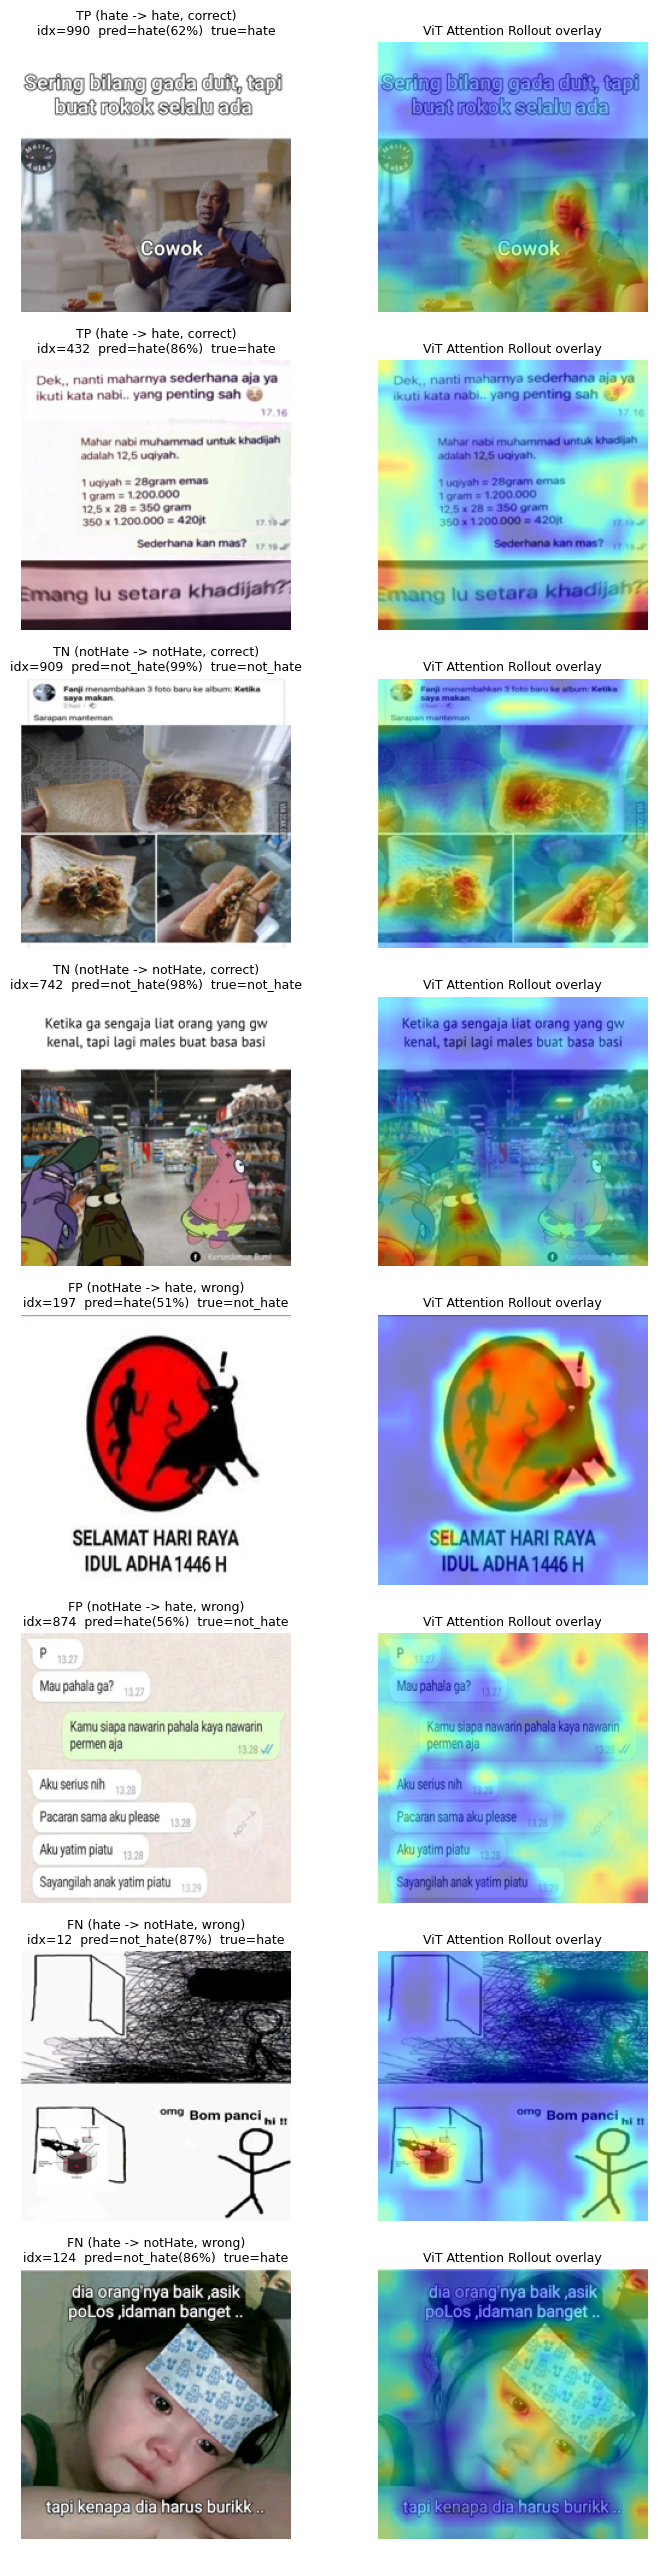

In [17]:
mask_tp = (all_preds == 1) & (all_labels == 1)
mask_tn = (all_preds == 0) & (all_labels == 0)
mask_fp = (all_preds == 1) & (all_labels == 0)
mask_fn = (all_preds == 0) & (all_labels == 1)

def pick_indices(mask, k, seed=0):
    pool = np.where(mask)[0]
    return np.random.RandomState(seed).choice(pool, size=min(k, len(pool)), replace=False)

picks = {
    "TP (hate -> hate, correct)":         pick_indices(mask_tp, 2),
    "TN (notHate -> notHate, correct)":   pick_indices(mask_tn, 2),
    "FP (notHate -> hate, wrong)":        pick_indices(mask_fp, 2),
    "FN (hate -> notHate, wrong)":        pick_indices(mask_fn, 2),
}

n_total = sum(len(v) for v in picks.values())
fig, axes = plt.subplots(n_total, 2, figsize=(8, 3.2*n_total))
if n_total == 1: axes = axes.reshape(1, 2)

row = 0
for cat, idx_list in picks.items():
    for i in idx_list:
        idx_global = int(all_idxs[i])
        img_path   = all_paths[i]
        pred_str   = "hate" if all_preds[i] == 1 else "not_hate"
        true_str   = "hate" if all_labels[i] == 1 else "not_hate"
        prob_pct   = all_probs[i] * 100

        img_pil = Image.open(img_path).convert("RGB")
        blended, _ = overlay_attention(img_pil, all_maps[i], alpha=0.5)

        axes[row, 0].imshow(img_pil.resize((CONFIG["img_size"], CONFIG["img_size"])))
        axes[row, 0].set_title(f"{cat}\nidx={idx_global}  pred={pred_str}({prob_pct:.0f}%)  true={true_str}", fontsize=9)
        axes[row, 0].axis("off")
        axes[row, 1].imshow(blended)
        axes[row, 1].set_title("ViT Attention Rollout overlay", fontsize=9)
        axes[row, 1].axis("off")
        row += 1

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rollout_visualizations.png", dpi=120, bbox_inches="tight")
plt.show()

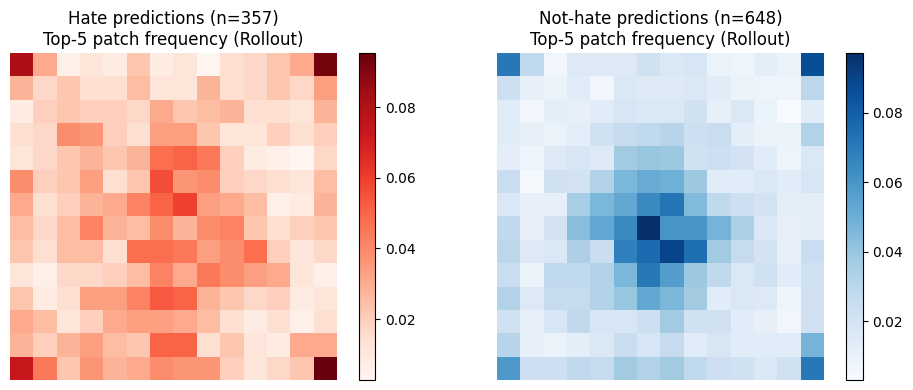

In [18]:
top_patches = []
for i in range(len(all_maps)):
    flat_i = all_maps[i].flatten()
    top_idx = np.argsort(-flat_i)[:5]
    coords = [(int(p // 14), int(p % 14), float(flat_i[p])) for p in top_idx]
    top_patches.append(coords)

hate_heatmap     = np.zeros((14, 14), dtype=np.float32)
not_hate_heatmap = np.zeros((14, 14), dtype=np.float32)
for i, coords in enumerate(top_patches):
    bag = hate_heatmap if all_preds[i] == 1 else not_hate_heatmap
    for r, c, _ in coords:
        bag[r, c] += 1

n_hate     = int((all_preds == 1).sum())
n_not_hate = int((all_preds == 0).sum())
if n_hate > 0:     hate_heatmap     /= n_hate
if n_not_hate > 0: not_hate_heatmap /= n_not_hate

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im0 = axes[0].imshow(hate_heatmap, cmap="Reds")
axes[0].set_title(f"Hate predictions (n={n_hate})\nTop-5 patch frequency (Rollout)")
axes[0].axis("off"); plt.colorbar(im0, ax=axes[0], fraction=0.046)
im1 = axes[1].imshow(not_hate_heatmap, cmap="Blues")
axes[1].set_title(f"Not-hate predictions (n={n_not_hate})\nTop-5 patch frequency (Rollout)")
axes[1].axis("off"); plt.colorbar(im1, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rollout_top_patches_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

In [19]:
analysis = {
    "config": {
        "top_k_patches": 5,
        "head_fusion":   CONFIG["head_fusion"],
        "discard_ratio": CONFIG["discard_ratio"],
    },
    "per_sample_top_patches": [
        {
            "idx":        int(all_idxs[i]),
            "pred_class": int(all_preds[i]),
            "true_label": int(all_labels[i]),
            "pred_prob":  float(all_probs[i]),
            "top5_patches": [{"row": int(r), "col": int(c), "score": float(s)} for (r,c,s) in top_patches[i]],
        }
        for i in range(len(all_maps))
    ],
    "aggregate_hate_top5_freq":     hate_heatmap.tolist(),
    "aggregate_nothate_top5_freq":  not_hate_heatmap.tolist(),
}
with open(OUTPUT_DIR / "rollout_top_patches.json", "w") as f:
    json.dump(analysis, f)
print(f"Saved: rollout_top_patches.json")

Saved: rollout_top_patches.json


In [20]:
final_summary = {
    "exp_id":      CONFIG["exp_id"],
    "ckpt_path":   str(CKPT_PATH),
    "n_samples":   int(len(all_maps)),
    "test_accuracy": float((all_preds == all_labels).mean()),
    "elapsed_min": float(elapsed / 60),
    "rollout_config": {
        "head_fusion":   CONFIG["head_fusion"],
        "discard_ratio": CONFIG["discard_ratio"],
    },
    "map_stats": {
        "shape":       list(all_maps.shape),
        "mean":        float(all_maps.mean()),
        "std":         float(all_maps.std()),
        "top10_share": float(top10.mean()),
        "top20_share": float(top20.mean()),
        "max":         float(all_maps.max()),
    },
}
with open(OUTPUT_DIR / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2, default=str)
with open(OUTPUT_DIR / "final_summary.json", "w") as f:
    json.dump(final_summary, f, indent=2)

print(f"\n{'='*72}\nKOMPONEN 3 (ROLLOUT) DONE\n{'='*72}")
print(f"Experiment        : {CONFIG['exp_id']}")
print(f"Samples processed : {len(all_maps)}")
print(f"Test accuracy     : {(all_preds == all_labels).mean():.4f}")
print(f"Top-10 share      : {top10.mean()*100:.1f}%  (uniform={10/196*100:.1f}%)")
print(f"Top-20 share      : {top20.mean()*100:.1f}%  (uniform={20/196*100:.1f}%)")
print(f"Max value         : {all_maps.max():.4f}")
print(f"Elapsed           : {elapsed/60:.1f} min")


KOMPONEN 3 (ROLLOUT) DONE
Experiment        : 2A.3_attention_rollout
Samples processed : 1005
Test accuracy     : 0.8149
Top-10 share      : 6.9%  (uniform=5.1%)
Top-20 share      : 12.8%  (uniform=10.2%)
Max value         : 0.0210
Elapsed           : 0.4 min
